# Exploratory Data Analysis: Dudley Employment Barriers

## Purpose

Explore how economic activity, qualifications, disability,
car availability and deprivation vary across Dudley neighbourhoods.

The analysis addresses the project question:

**What does Dudley’s labour-market profile suggest about the
different support people may need to move into work?**

## Data and scope

This notebook uses `dudley_combined_prepared.csv`, containing
199 geographically compatible LSOAs and 105 columns.

The dataset combines Census 2021 measures with historical
IoD2019 deprivation measures. The 199 shared areas were verified
against the official ONS boundary lookup.

Four Census areas without matching deprivation codes were excluded.
The combined dataset therefore does not cover all 203 Census areas
in Dudley.

## Planned exploration

- Produce descriptive statistics for selected measures.
- Examine distributions and differences between areas.
- Investigate unusual values without automatically removing them.
- Explore relationships to inform later hypothesis testing.
- Record findings and limitations alongside the analysis.

## Ethical considerations and interpretation

These are area-level statistics. Patterns between neighbourhoods
do not establish individual circumstances or causes of unemployment.

Disability does not imply inability or unwillingness to work.
Having no qualifications does not mean having no skills.
Having no car does not automatically mean poor transport access.

Economic activity percentages use residents aged 16 and over as
their denominator. The unemployment population share is not an
unemployment rate. Selected inactivity categories do not represent
total economic inactivity.

Car availability percentages describe households, while other
Census percentages describe people. Deprivation measures provide
historical context and should not be presented as current conditions.

Findings will use respectful language and distinguish observed
patterns from possible explanations.

---

# Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Dudley employment barriers\\jupyter_notebooks'

We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [3]:
current_dir = os.getcwd()
current_dir

'c:\\Dudley employment barriers'

## 1. Load and inspect the prepared dataset

Load `dudley_combined_prepared.csv` and confirm that it contains
the expected 199 LSOAs and 105 columns.

Preview the first few rows to check that the file has loaded correctly.

In [4]:
# Developed with ChatGPT assistance to load and inspect the dataset.

import pandas as pd

# Load the prepared dataset.
data_path = "cleaned_datasets/dudley_combined_prepared.csv"
df = pd.read_csv(data_path)

# Check the dimensions and preview the first five rows.
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 199
Columns: 105


,Economic_Total_16_Plus,Economically_Active_Excl_FT_Students,Employed_Excl_FT_Students,Unemployed_Excl_FT_Students,Inactive_Student,Inactive_Home_Or_Family,Inactive_Long_Term_Sick_Or_Disabled,Inactive_Other,LSOA_Code,LSOA_Name,...,IoD2019_Indoors_Sub_domain_Rank,IoD2019_Indoors_Sub_domain_Decile,IoD2019_Outdoors_Sub_domain_Score,IoD2019_Outdoors_Sub_domain_Rank,IoD2019_Outdoors_Sub_domain_Decile,IoD2019_Total_population_mid_2015_excluding_prisoners,IoD2019_Dependent_Children_aged_0_15_mid_2015_excluding_prisoners,IoD2019_Population_aged_16_59_mid_2015_excluding_prisoners,IoD2019_Older_population_aged_60_and_over_mid_2015_excluding_prisoners,IoD2019_Working_age_population_18_59_64_for_use_with_Employment_Deprivation_Domain_excluding_prisoners
0,1637,970,888,82,97,164,73,70,E01009763,Dudley 001A,...,14369,5,-0.212,18843,6,1817,458,1073,286,1038
1,1264,759,731,28,35,50,35,31,E01009764,Dudley 001B,...,3121,1,-0.035,15873,5,1380,219,800,361,810
2,1265,748,699,49,35,69,66,28,E01009767,Dudley 001C,...,9455,3,-0.167,18091,6,1519,276,836,407,848
3,1431,701,618,83,78,119,148,59,E01009769,Dudley 001D,...,5299,2,0.532,8066,3,1711,384,944,383,955
4,1214,664,625,39,41,73,69,50,E01009770,Dudley 001E,...,6292,2,-0.275,19903,7,1487,262,817,408,826


### Findings

The prepared dataset loaded successfully with 199 rows and 105 columns,
matching the expected dimensions.

The preview shows LSOA codes and names alongside Census counts and
historical IoD2019 measures.

The dataset covers the 199 geographically compatible LSOAs retained
during preparation, rather than all 203 Census areas in Dudley.

---

## 2. Check the dataset structure

Inspect the column names and data types before selecting measures
for exploration.

Confirm that each LSOA code appears once and check for missing values
or duplicate rows after loading the saved CSV.

In [5]:
# Developed with ChatGPT assistance to inspect the dataset structure.

# Summarise area identifiers, duplicate rows and missing values.
print(
    f"Unique LSOA codes: "
    f"{df['LSOA_Code'].nunique()}"
)
print(
    f"Missing LSOA codes: "
    f"{df['LSOA_Code'].isna().sum()}"
)
print(
    f"Duplicate LSOA codes: "
    f"{df['LSOA_Code'].duplicated().sum()}"
)
print(f"Duplicate rows: {df.duplicated().sum()}")
print(
    f"Total missing values: "
    f"{df.isna().sum().sum()}"
)

# Show every column with its data type and missing-value count.
column_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).to_numpy(),
    "Missing_Values": df.isna().sum().to_numpy()
})

print("\nColumn summary:")
print(column_summary.to_string(index=False))

Unique LSOA codes: 199
Missing LSOA codes: 0
Duplicate LSOA codes: 0
Duplicate rows: 0
Total missing values: 0

Column summary:
                                                                                                Column Data_Type  Missing_Values
                                                                                Economic_Total_16_Plus     int64               0
                                                                  Economically_Active_Excl_FT_Students     int64               0
                                                                             Employed_Excl_FT_Students     int64               0
                                                                           Unemployed_Excl_FT_Students     int64               0
                                                                                      Inactive_Student     int64               0
                                                                               Inactive_Home_Or_Fa

### Findings

The dataset contains 199 unique LSOA codes, with no missing or
duplicate codes. No duplicate rows or missing values were detected
across the 105 columns.

Area codes and names loaded as text. Counts, deprivation ranks and
deciles loaded as integers, while percentages and deprivation scores
loaded as decimal numbers.

No structural issues were identified by these checks. Numeric data
types alone do not confirm that values fall within valid ranges;
selected measures will be examined during exploration.

---

## 3. Descriptive statistics for selected Census measures

Summarise employment, unemployment population share, selected reasons
for economic inactivity, qualifications, disability and car availability.

Calculate the mean, standard deviation, minimum, quartiles and maximum
across the 199 included LSOAs. Check whether any selected percentages
fall outside the valid range of 0 to 100.

Each LSOA receives equal weight in these summaries. The mean therefore
describes the average neighbourhood percentage, not the overall
percentage of Dudley residents or households.

Economic activity measures use residents aged 16 and over as their
denominator. Employment and unemployment counts exclude full-time
students. The unemployment population share is not an unemployment rate.

Car availability measures describe households. The other selected
percentages describe residents aged 16 and over, using their respective
source totals. Deprivation measures will be summarised separately
because they use different scales.

In [6]:
# Developed with ChatGPT assistance to summarise Census measures.

# Select measures relevant to the project question.
census_measures = [
    "Employed_Excl_FT_Students_Pct",
    "Unemployed_Excl_FT_Students_Pct",
    "Inactive_Home_Or_Family_Pct",
    "Inactive_Long_Term_Sick_Or_Disabled_Pct",
    "No_Qualifications_Pct",
    "Level_4_And_Above_Pct",
    "Disabled_16_Plus_Pct",
    "Limited_A_Lot_16_Plus_Pct",
    "No_Car_Van_Households_Pct"
]

# Summarise variation across LSOAs.
census_summary = (
    df[census_measures].describe().T
)

census_summary = census_summary.rename(
    columns={
        "count": "Areas",
        "mean": "Mean",
        "std": "Std_Dev",
        "min": "Minimum",
        "25%": "Q1",
        "50%": "Median",
        "75%": "Q3",
        "max": "Maximum"
    }
)

# Count values outside the valid percentage range.
census_summary["Outside_0_100"] = (
    (df[census_measures] < 0)
    | (df[census_measures] > 100)
).sum()

# Round only the displayed summary, preserving the original data.
print(census_summary.round(2).to_string())

                                         Areas   Mean  Std_Dev  Minimum     Q1  Median     Q3  Maximum  Outside_0_100
Employed_Excl_FT_Students_Pct            199.0  53.87     5.07    41.07  50.54   53.57  56.82    70.26              0
Unemployed_Excl_FT_Students_Pct          199.0   3.15     1.51     0.49   2.06    2.93   3.94    10.40              0
Inactive_Home_Or_Family_Pct              199.0   5.08     2.58     1.29   2.99    4.35   6.74    13.59              0
Inactive_Long_Term_Sick_Or_Disabled_Pct  199.0   4.44     2.49     0.30   2.42    4.07   6.21    11.58              0
No_Qualifications_Pct                    199.0  22.98     5.79    10.19  18.30   23.39  27.37    36.96              0
Level_4_And_Above_Pct                    199.0  24.99     6.85    13.76  19.66   24.04  29.24    49.65              0
Disabled_16_Plus_Pct                     199.0  22.28     3.87    13.17  19.77   22.02  24.88    36.73              0
Limited_A_Lot_16_Plus_Pct                199.0   9.73   

### Findings

All nine selected measures contain values for 199 LSOAs, with no
percentages outside the valid range of 0 to 100.

- Employment excluding full-time students averages 53.87% of residents
  aged 16 and over across neighbourhoods, ranging from 41.07% to 70.26%.
- The unemployment population share averages 3.15%, ranging from 0.49%
  to 10.40%. This is not an unemployment rate.
- Inactivity due to looking after home or family averages 5.08%.
  Inactivity due to long-term sickness or disability averages 4.44%.
  These categories do not represent total economic inactivity.
- The percentage with no qualifications ranges from 10.19% to 36.96%,
  while Level 4 or above qualifications range from 13.76% to 49.65%.
- Disabled residents account for an average neighbourhood share of
  22.28%. Those whose activities are limited a lot account for 9.73%
  of all residents aged 16 and over, not 9.73% of disabled residents.
- Households without a car or van show the greatest spread among
  these measures: 3.23% to 50.58%, with a standard deviation of
  9.20 percentage points.

These results show differences between neighbourhoods but do not
explain their causes. The means give each LSOA equal weight and
should not be presented as overall Dudley percentages.

The higher and lower values will be explored further rather than
automatically treated as errors or removed.

---

## 4. Descriptive statistics for historical deprivation

Summarise the IoD2019 Index of Multiple Deprivation (IMD) score
and selected domain scores covering income, employment, education,
and health and disability.

These measures provide historical context for the Census 2021
patterns. They do not describe current deprivation.

Summarise each measure on its original scale. Scores from different
domains are not directly comparable and should not be averaged
together.

Count the included LSOAs in each national IMD decile. Decile 1
represents the most deprived tenth of English LSOAs, while decile 10
represents the least deprived tenth.

The summaries give each included LSOA equal weight. Decile counts
describe areas, not the number or percentage of residents.

In [7]:
# Developed with ChatGPT assistance to summarise historical deprivation.

# Keep deprivation measures separate from Census percentages.
deprivation_measures = [
    "IoD2019_IMD_Score",
    "IoD2019_Income_Score_rate",
    "IoD2019_Employment_Score_rate",
    (
        "IoD2019_Education_Skills_"
        "and_Training_Score"
    ),
    (
        "IoD2019_Health_Deprivation_"
        "and_Disability_Score"
    )
]

deprivation_summary = (
    df[deprivation_measures].describe().T
)

deprivation_summary = deprivation_summary.rename(
    columns={
        "count": "Areas",
        "mean": "Mean",
        "std": "Std_Dev",
        "min": "Minimum",
        "25%": "Q1",
        "50%": "Median",
        "75%": "Q3",
        "max": "Maximum"
    }
)

print(
    "Historical deprivation scores "
    "(original scales):"
)
print(deprivation_summary.round(3).to_string())

# Check decile values before counting areas in each category.
imd_deciles = df["IoD2019_IMD_Decile"]
invalid_deciles = (
    ~imd_deciles.isin(range(1, 11))
).sum()

print(
    "\nInvalid or missing IMD deciles: "
    f"{invalid_deciles}"
)

decile_counts = (
    imd_deciles.value_counts()
    .reindex(range(1, 11), fill_value=0)
    .sort_index()
    .rename_axis("IMD_Decile")
    .rename("Number_of_LSOAs")
)

print("\nIncluded LSOAs by national IMD decile:")
print(decile_counts.to_string())

Historical deprivation scores (original scales):
                                                 Areas    Mean  Std_Dev  Minimum      Q1  Median      Q3  Maximum
IoD2019_IMD_Score                                199.0  22.946   14.400    3.360   9.965  21.239  33.214   63.363
IoD2019_Income_Score_rate                        199.0   0.148    0.094    0.020   0.066   0.133   0.216    0.408
IoD2019_Employment_Score_rate                    199.0   0.117    0.063    0.021   0.062   0.106   0.164    0.297
IoD2019_Education_Skills_and_Training_Score      199.0  27.076   19.260    1.440  10.016  22.556  42.250   92.175
IoD2019_Health_Deprivation_and_Disability_Score  199.0   0.253    0.523   -0.927  -0.150   0.215   0.641    1.722

Invalid or missing IMD deciles: 0

Included LSOAs by national IMD decile:
IMD_Decile
1     20
2     30
3     26
4     21
5     21
6      8
7     16
8     20
9     18
10    19


### Findings

All five selected deprivation measures contain values for 199 LSOAs.
No invalid or missing IMD deciles were detected.

IMD scores range from 3.360 to 63.363, with a median of 21.239,
showing variation in historical deprivation across the included areas.

All ten national IMD deciles are represented:
- 20 LSOAs fall within the most deprived national decile.
- 50 LSOAs fall within the most deprived two deciles, representing
  25.1% of the 199 included areas.
- 19 LSOAs fall within the least deprived national decile.
- Decile 2 contains the largest number of included LSOAs, with 30.

Income deprivation scores range from 0.020 to 0.408, and employment
deprivation scores range from 0.021 to 0.297. These retain their
original rate scales and source-specific definitions; the employment
deprivation measure is not the Census unemployment population share.

Education scores range from 1.440 to 92.175. Health deprivation and
disability scores range from -0.927 to 1.722. Negative values on the
standardised health deprivation scale are not automatically errors.

The domains use different scales, so their score magnitudes should
not be compared directly.

These findings describe historical IoD2019 deprivation among the
199 included LSOAs. The decile percentages refer to areas, not
residents, and do not cover all 203 Census areas in Dudley.

---

## 5. Distributions of selected Census measures

Use histograms to examine how the selected percentages are distributed
across the 199 included LSOAs.

Each panel shows one measure. The horizontal axis shows its percentage
and the vertical axis shows the number of neighbourhoods.

Dashed lines mark the mean and median. Their positions help us explore
possible asymmetry alongside the shape of each distribution.

Each panel uses its own horizontal scale to make its distribution
visible. Compare the axis values when assessing differences in spread.

These plots describe neighbourhoods, with each LSOA counted once.
They do not show individual residents or establish causal relationships.

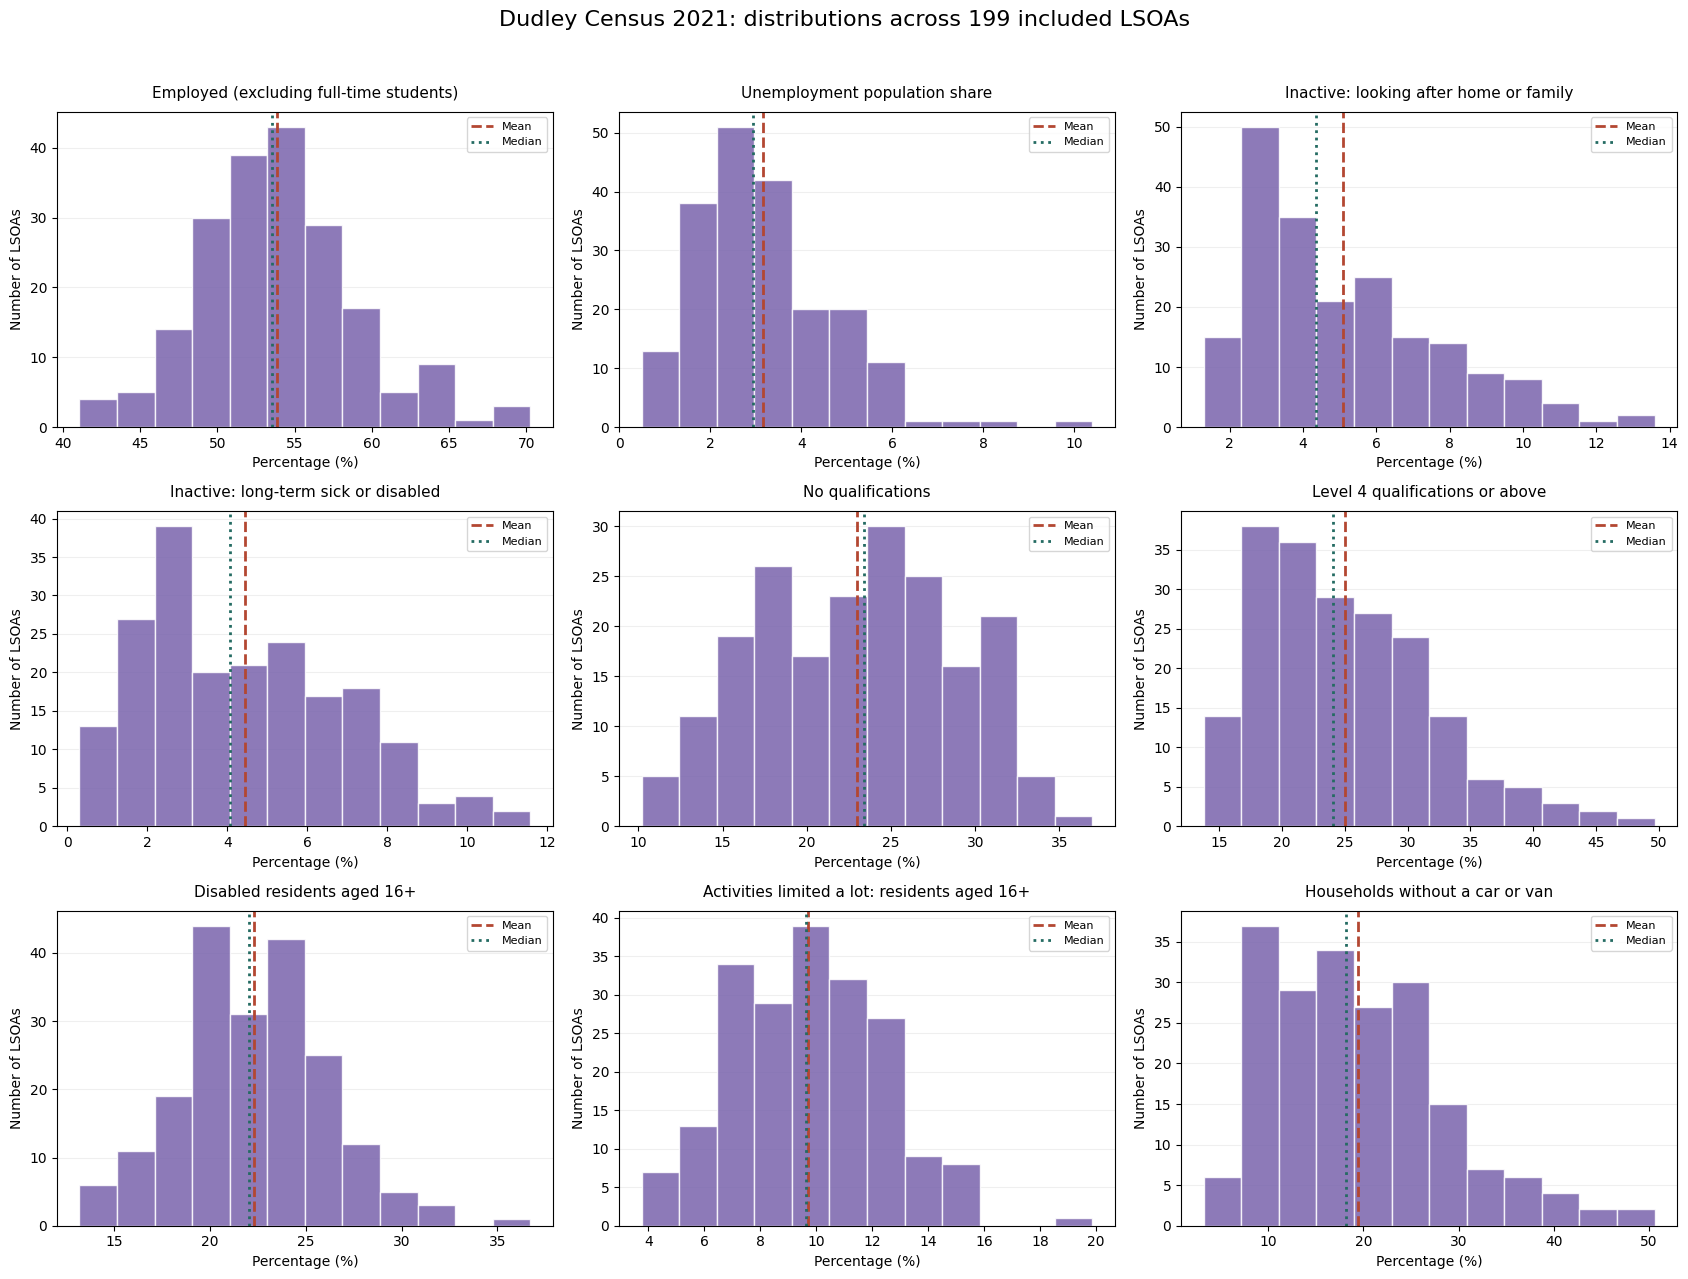

In [8]:
# Developed with ChatGPT assistance to visualise Census distributions.

%matplotlib inline
import matplotlib.pyplot as plt

# Readable labels in the same order as census_measures.
measure_labels = [
    "Employed (excluding full-time students)",
    "Unemployment population share",
    "Inactive: looking after home or family",
    "Inactive: long-term sick or disabled",
    "No qualifications",
    "Level 4 qualifications or above",
    "Disabled residents aged 16+",
    (
        "Activities limited a lot: "
        "residents aged 16+"
    ),
    "Households without a car or van"
]

fig, axes = plt.subplots(
    3, 3, figsize=(17, 13)
)

for ax, column, label in zip(
    axes.flat,
    census_measures,
    measure_labels
):
    values = df[column]

    ax.hist(
        values,
        bins=12,
        color="#7963AC",
        edgecolor="white",
        alpha=0.85
    )
    ax.axvline(
        values.mean(),
        color="#B34732",
        linestyle="--",
        linewidth=2,
        label="Mean"
    )
    ax.axvline(
        values.median(),
        color="#246B62",
        linestyle=":",
        linewidth=2,
        label="Median"
    )

    ax.set_title(label, fontsize=11, pad=10)
    ax.set_xlabel("Percentage (%)")
    ax.set_ylabel("Number of LSOAs")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Dudley Census 2021: distributions "
    "across 199 included LSOAs",
    fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.96])

from pathlib import Path

# Save the figure in a separate visualisations folder.
Path("visualisations").mkdir(exist_ok=True)

fig.savefig(
    "visualisations/"
    "census_measure_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Findings

Employment percentages are concentrated around the low-to-mid 50s,
with the mean and median close together.

Unemployment population share, inactivity due to home or family
responsibilities, and inactivity due to long-term sickness or disability
show right-tailed distributions. Most neighbourhoods have lower values,
while a smaller number have considerably higher shares.

Level 4 or above qualifications and households without a car or van
also show right tails, with their means above their medians.

The no-qualifications distribution is broadly spread, with less obvious
asymmetry. Disability and activities-limited-a-lot percentages are more
centrally concentrated, although a few areas have higher values.

Potentially unusual values include unemployment population shares
above 8%, households without a car or van approaching 50%, and
disability shares above 35%. These warrant closer inspection but
are not automatically errors.

Histogram shapes depend partly on the chosen bins. These are visual
observations, not formal tests of normality or evidence of causation.

---

## 6. Flag unusual Census values for investigation

Use the interquartile range (IQR) to flag unusually low or high values
for each selected Census measure.

The IQR is the difference between the first and third quartiles.
Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged.

This is an exploratory rule, not a test for data errors. Skewed
distributions can contain valid observations outside these limits.

Report the limits and number of flagged areas for each measure,
then identify the affected LSOAs. An area may be flagged for more
than one measure.

Retain all observations while investigating their context.

In [9]:
# Developed with ChatGPT assistance to flag unusual Census values.

iqr_results = []
flagged_tables = []

for column in census_measures:
    values = df[column]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    below = values < lower_limit
    above = values > upper_limit
    flagged = below | above

    iqr_results.append({
        "Measure": column,
        "Lower_Limit": lower_limit,
        "Upper_Limit": upper_limit,
        "Below": int(below.sum()),
        "Above": int(above.sum()),
        "Total_Flagged": int(flagged.sum())
    })

    area_details = df.loc[
        flagged, ["LSOA_Code", "LSOA_Name"]
    ].copy()
    area_details["Measure"] = column
    area_details["Value_Pct"] = values.loc[flagged]
    area_details["Direction"] = [
        "Below" if value < lower_limit else "Above"
        for value in values.loc[flagged]
    ]

    flagged_tables.append(area_details)

iqr_summary = pd.DataFrame(iqr_results)
flagged_values = pd.concat(flagged_tables, ignore_index=True)

print("IQR screening summary:")
print(iqr_summary.round(2).to_string(index=False))

print("\nFlagged area-measure observations:")
print(flagged_values.round(2).to_string(index=False))

print(
    "\nUnique LSOAs flagged:",
    flagged_values["LSOA_Code"].nunique()
)
print(f"Rows retained in the dataset: {len(df)}")

IQR screening summary:
                                Measure  Lower_Limit  Upper_Limit  Below  Above  Total_Flagged
          Employed_Excl_FT_Students_Pct        41.11        66.24      1      4              5
        Unemployed_Excl_FT_Students_Pct        -0.76         6.76      0      3              3
            Inactive_Home_Or_Family_Pct        -2.64        12.37      0      2              2
Inactive_Long_Term_Sick_Or_Disabled_Pct        -3.26        11.88      0      0              0
                  No_Qualifications_Pct         4.69        40.99      0      0              0
                  Level_4_And_Above_Pct         5.29        43.61      0      3              3
                   Disabled_16_Plus_Pct        12.09        32.56      0      1              1
              Limited_A_Lot_16_Plus_Pct         1.98        17.27      0      1              1
              No_Car_Van_Households_Pct        -7.37        44.54      0      3              3

Flagged area-measure obser

### Findings

The IQR screening flagged 18 area-measure observations across
13 unique LSOAs. All 199 areas remain in the dataset.

- Employment flagged five areas: four above the upper limit and
  one below the lower limit. Dudley 013E was only slightly below
  the lower threshold, at 41.07% compared with 41.11%.
- Three areas had high unemployment population shares: Dudley 022A,
  Dudley 037B and Dudley 039B. These same areas also had high
  percentages of households without a car or van.
- Dudley 013E was flagged for a high disability share (36.73%) and
  a high share whose activities are limited a lot (19.88%).
  These measures overlap because the latter is a disability subgroup.
- Two areas were flagged for high inactivity due to home or family
  responsibilities, and three for high Level 4 or above qualifications.
- No values were flagged for no qualifications or inactivity due
  to long-term sickness or disability.

The overlap between high unemployment population shares and households
without a car warrants further exploration. It does not establish that
the same individuals experience both circumstances or that one causes
the other.

Negative lower IQR limits are mathematical thresholds, not observed
negative percentages. Being flagged does not establish a data error,
and not being flagged does not guarantee that a value is correct.

The flagged areas will be examined using their underlying counts and
denominators before drawing further conclusions. No values were removed.

---

## 7. Inspect counts and denominators for flagged values

Examine the underlying counts and source-specific denominators for
the observations flagged by the IQR screening.

Recalculate each flagged percentage as its count divided by its
denominator, multiplied by 100. Compare the result with the stored
percentage and check that the denominator is positive and the count
falls between zero and its total.

This checks arithmetic consistency within the prepared dataset.
It is not an independent comparison with the original source files.

Retain all areas. An unusual percentage may reflect a real local
pattern, and these checks alone cannot explain its cause.

In [10]:
# Developed with ChatGPT assistance to inspect flagged percentages.

# Match each percentage to its count and source-specific denominator.
measure_sources = {
    "Employed_Excl_FT_Students_Pct": (
        "Employed_Excl_FT_Students",
        "Economic_Total_16_Plus"
    ),
    "Unemployed_Excl_FT_Students_Pct": (
        "Unemployed_Excl_FT_Students",
        "Economic_Total_16_Plus"
    ),
    "Inactive_Home_Or_Family_Pct": (
        "Inactive_Home_Or_Family",
        "Economic_Total_16_Plus"
    ),
    "Inactive_Long_Term_Sick_Or_Disabled_Pct": (
        "Inactive_Long_Term_Sick_Or_Disabled",
        "Economic_Total_16_Plus"
    ),
    "No_Qualifications_Pct": (
        "No_Qualifications",
        "Qualifications_Total_16_Plus"
    ),
    "Level_4_And_Above_Pct": (
        "Level_4_And_Above",
        "Qualifications_Total_16_Plus"
    ),
    "Disabled_16_Plus_Pct": (
        "Disabled_16_Plus",
        "Disability_Total_16_Plus"
    ),
    "Limited_A_Lot_16_Plus_Pct": (
        "Limited_A_Lot_16_Plus",
        "Disability_Total_16_Plus"
    ),
    "No_Car_Van_Households_Pct": (
        "No_Car_Van_Households",
        "Total_Households"
    )
}

# Use LSOA codes to look up each area's counts and totals.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.set_index.html
area_lookup = df.set_index("LSOA_Code")
inspection_rows = []

# Iterate through the flagged area-measure observations.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iterrows.html
for _, flagged_row in flagged_values.iterrows():
    measure = flagged_row["Measure"]
    count_column, total_column = (
        measure_sources[measure]
    )

    # Select the area by its LSOA code.
    area = area_lookup.loc[
        flagged_row["LSOA_Code"]
    ]

    count = area[count_column]
    total = area[total_column]
    stored_pct = area[measure]

    # Recalculate the percentage, avoiding division by zero.
    recalculated_pct = (
        count / total * 100
        if total > 0
        else float("nan")
    )
    difference = abs(stored_pct - recalculated_pct)

    # Check count validity and agreement within a small numeric tolerance.
    inspection_rows.append({
        "LSOA_Code": flagged_row["LSOA_Code"],
        "LSOA_Name": flagged_row["LSOA_Name"],
        "Measure": measure,
        "Count": count,
        "Denominator": total_column,
        "Total": total,
        "Stored_Pct": stored_pct,
        "Recalculated_Pct": recalculated_pct,
        "Valid_Count_And_Total": bool(
            total > 0 and 0 <= count <= total
        ),
        "Calculation_Matches": bool(
            difference < 0.000001
        )
    })

# Convert the inspection records into a table.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html
flagged_inspection = pd.DataFrame(inspection_rows)

# Round only the displayed results and print all columns.
print(
    flagged_inspection.round(4)
    .to_string(index=False)
)

# Summarise failed checks without changing or removing any rows.
print(
    "\nInvalid counts or denominators:",
    (
        ~flagged_inspection["Valid_Count_And_Total"]
    ).sum()
)
print(
    "Percentage calculation mismatches:",
    (
        ~flagged_inspection["Calculation_Matches"]
    ).sum()
)
print(f"Rows retained: {len(df)}")

LSOA_Code   LSOA_Name                         Measure  Count                  Denominator  Total  Stored_Pct  Recalculated_Pct  Valid_Count_And_Total  Calculation_Matches
E01009780 Dudley 009A   Employed_Excl_FT_Students_Pct   1238       Economic_Total_16_Plus   1762     70.2611           70.2611                   True                 True
E01009784 Dudley 009B   Employed_Excl_FT_Students_Pct    872       Economic_Total_16_Plus   1286     67.8072           67.8072                   True                 True
E01009886 Dudley 013E   Employed_Excl_FT_Students_Pct    667       Economic_Total_16_Plus   1624     41.0714           41.0714                   True                 True
E01009731 Dudley 023A   Employed_Excl_FT_Students_Pct    899       Economic_Total_16_Plus   1320     68.1061           68.1061                   True                 True
E01009730 Dudley 028D   Employed_Excl_FT_Students_Pct    864       Economic_Total_16_Plus   1254     68.8995           68.8995                   

### Findings

All 18 flagged area-measure observations have positive denominators
and counts between zero and their respective totals. Every recalculated
percentage matches its stored value within the specified tolerance.

The flagged values are therefore internally consistent with the
counts and denominators in the prepared dataset. These checks do
not independently verify the original source data or explain why
the areas have unusual values.

For example:
- Dudley 022A has 173 unemployed residents excluding full-time students
  out of 1,664 residents aged 16 and over, giving a population share
  of 10.40%.
- Dudley 039B has 481 households without a car or van out of 951
  households, giving 50.58%.
- Dudley 013E has 595 disabled residents out of a disability-source
  total of 1,620 residents aged 16 and over, giving 36.73%.

Dudley 013E has different totals in the economic activity and
disability sources: 1,624 and 1,620 respectively. Each percentage
uses its own source-specific denominator. This check does not
establish the reason for that difference.

No arithmetic or count-range problems were detected among the
flagged observations. All 199 LSOAs are retained for further analysis.

---

## 8. Compare profiles of flagged neighbourhoods

Use a heatmap to compare the 13 flagged LSOAs across the nine selected
Census measures.

Each value shows the difference between an area's percentage and the
median percentage across all 199 included LSOAs, in percentage points.

Positive values indicate a share above the median; negative values
indicate a share below it. The same colour scale is used throughout.

These differences describe area profiles, not an overall disadvantage
score. A higher value has a different meaning for each measure.
Disability measures overlap, and household percentages describe a
different population from resident percentages.

The areas were selected because at least one measure was flagged.
Patterns in this subset should not be generalised to all Dudley areas.

Save the chart in the visualisations folder.

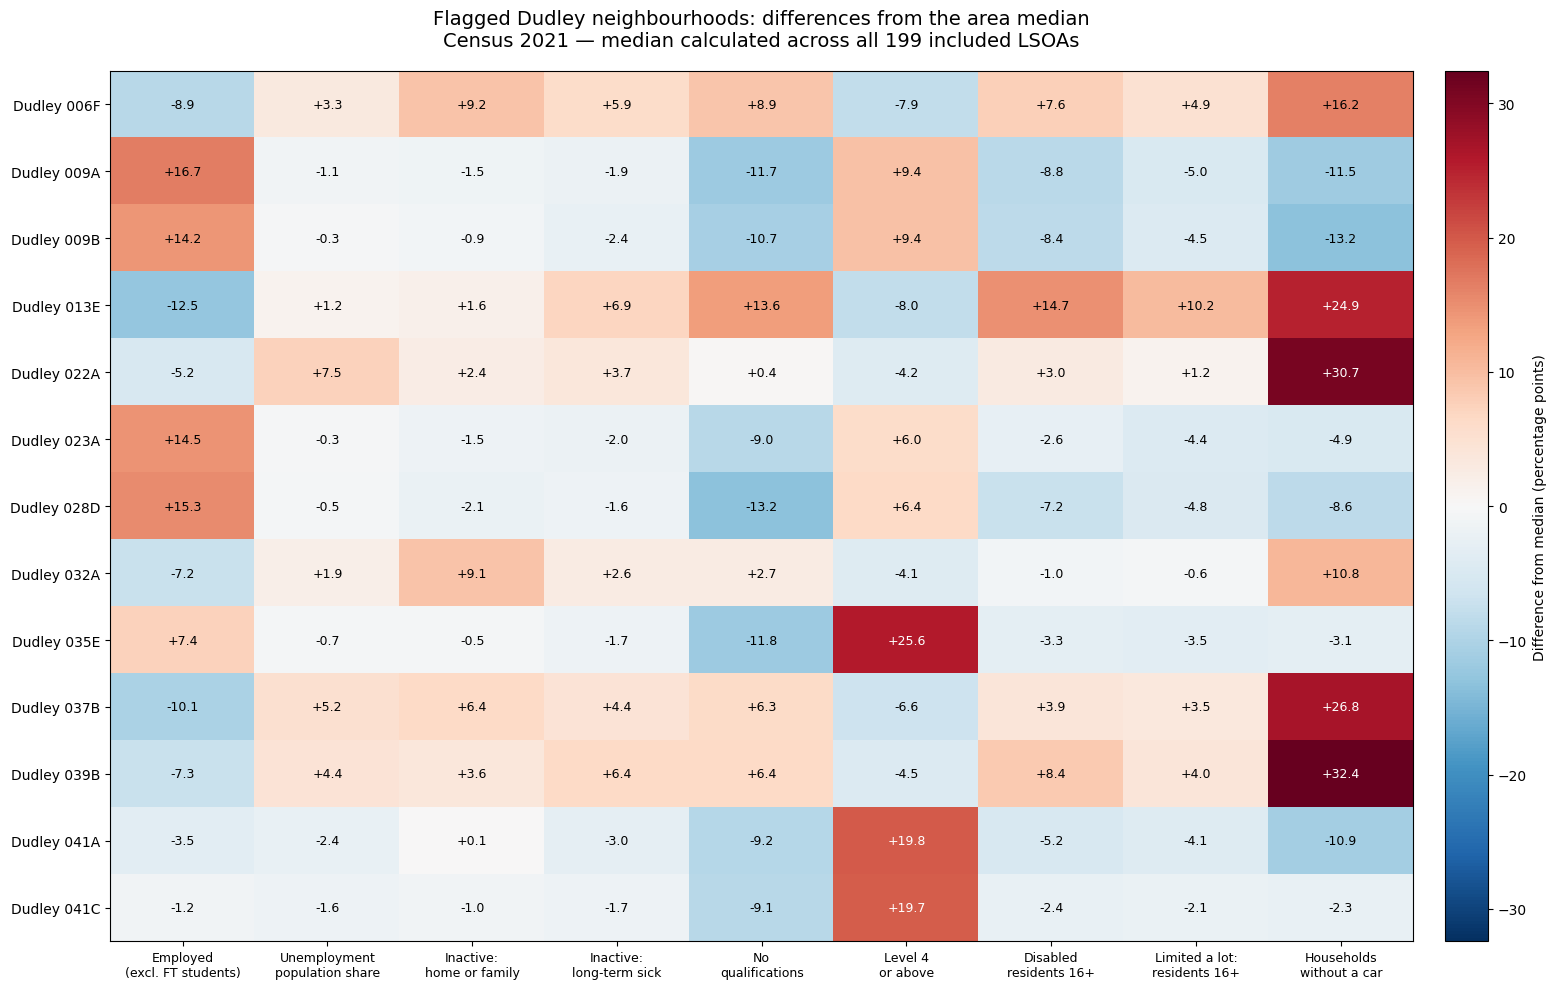

Saved: visualisations/flagged_area_profiles.png


In [11]:
%matplotlib inline

# Developed with ChatGPT assistance to compare flagged area profiles.

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Select the flagged areas once each and sort them by name.
flagged_codes = flagged_values["LSOA_Code"].unique()

flagged_profiles = (
    df.loc[df["LSOA_Code"].isin(flagged_codes)]
    .sort_values("LSOA_Name")
    .set_index("LSOA_Name")[census_measures]
)

# Subtract each measure's median across all 199 areas.
# Axis alignment matches each median to the correct column.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sub.html
median_differences = flagged_profiles.sub(
    df[census_measures].median(),
    axis="columns"
)

chart_labels = [
    "Employed\n(excl. FT students)",
    "Unemployment\npopulation share",
    "Inactive:\nhome or family",
    "Inactive:\nlong-term sick",
    "No\nqualifications",
    "Level 4\nor above",
    "Disabled\nresidents 16+",
    "Limited a lot:\nresidents 16+",
    "Households\nwithout a car"
]

# Centre the colour scale on zero with equal positive/negative limits.
colour_limit = float(
    np.abs(median_differences.to_numpy()).max()
)

fig, ax = plt.subplots(figsize=(17, 10))

# Render the matrix using one shared colour scale.
# Reference:
# https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.imshow.html
heatmap = ax.imshow(
    median_differences.to_numpy(),
    cmap="RdBu_r",
    vmin=-colour_limit,
    vmax=colour_limit,
    aspect="auto"
)

ax.set_xticks(range(len(chart_labels)))
ax.set_xticklabels(chart_labels, fontsize=9)
ax.set_yticks(range(len(median_differences)))
ax.set_yticklabels(
    median_differences.index,
    fontsize=10
)

# Annotate each cell with its percentage-point difference.
for row in range(median_differences.shape[0]):
    for column in range(median_differences.shape[1]):
        value = median_differences.iloc[row, column]
        text_colour = (
            "white"
            if abs(value) > colour_limit * 0.55
            else "black"
        )
        ax.text(
            column,
            row,
            f"{value:+.1f}",
            ha="center",
            va="center",
            color=text_colour,
            fontsize=9
        )

ax.set_title(
    "Flagged Dudley neighbourhoods: "
    "differences from the area median\n"
    "Census 2021 — median calculated "
    "across all 199 included LSOAs",
    fontsize=14,
    pad=18
)

colour_bar = fig.colorbar(
    heatmap,
    ax=ax,
    pad=0.02
)
colour_bar.set_label(
    "Difference from median (percentage points)"
)

fig.tight_layout()

Path("visualisations").mkdir(exist_ok=True)
figure_path = (
    "visualisations/flagged_area_profiles.png"
)
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print(f"Saved: {figure_path}")

### Findings

The flagged neighbourhoods show different combinations of characteristics.
All differences below are percentage points relative to the median
across the 199 included LSOAs.

- Dudley 022A, 037B and 039B have above-median unemployment population
  shares and households without a car. Their no-car shares are
  30.7, 26.8 and 32.4 percentage points above the median respectively.
  Employment shares are below the median in all three areas.
- Dudley 013E combines lower employment (-12.5 points) with higher
  disability (+14.7), no qualifications (+13.6) and households
  without a car (+24.9).
- Dudley 006F and 032A both have high home or family inactivity
  (+9.2 and +9.1 points), but their disability profiles differ:
  +7.6 points in 006F compared with -1.0 in 032A.
- Dudley 009A, 009B, 023A and 028D have higher employment shares,
  lower no-qualification shares and higher Level 4 or above shares
  than the respective medians.
- Dudley 035E has a particularly high Level 4 or above share
  (+25.6 points). However, higher qualifications do not always
  coincide with above-median employment: Dudley 041A and 041C have
  high Level 4 shares but slightly below-median employment shares.

These contrasting profiles suggest that further exploration should
consider combinations of characteristics rather than a single measure.

The heatmap does not identify individual support needs or establish
causal relationships. Age composition and other unmeasured factors
may contribute to the patterns. Findings from these deliberately
selected areas cannot be generalised to all neighbourhoods.

Colours indicate direction and size of differences, not whether
an area is better or worse overall.

---

## 9. Explore relationships between selected Census measures

Calculate Spearman correlations across all 199 included LSOAs.

Spearman correlation uses ranks to describe whether higher values
of one measure tend to occur alongside higher or lower values of
another. It can capture monotonic relationships without requiring
a straight-line pattern.

Values range from -1 to +1:
- Positive values indicate that the measures tend to increase together.
- Negative values indicate that one tends to decrease as the other increases.
- Values near zero indicate a weak monotonic relationship, but do not
  rule out other types of relationship.

Use the nine selected Census measures. Keep this exploration separate
from formal hypothesis testing; no significance tests are performed here.

Some measures share denominators or overlap in their definitions.
For example, residents whose activities are limited a lot are a subset
of disabled residents. These connections can contribute to correlations.

Area-level associations do not establish individual relationships or
causation. Age composition and other unmeasured factors may influence
the patterns.

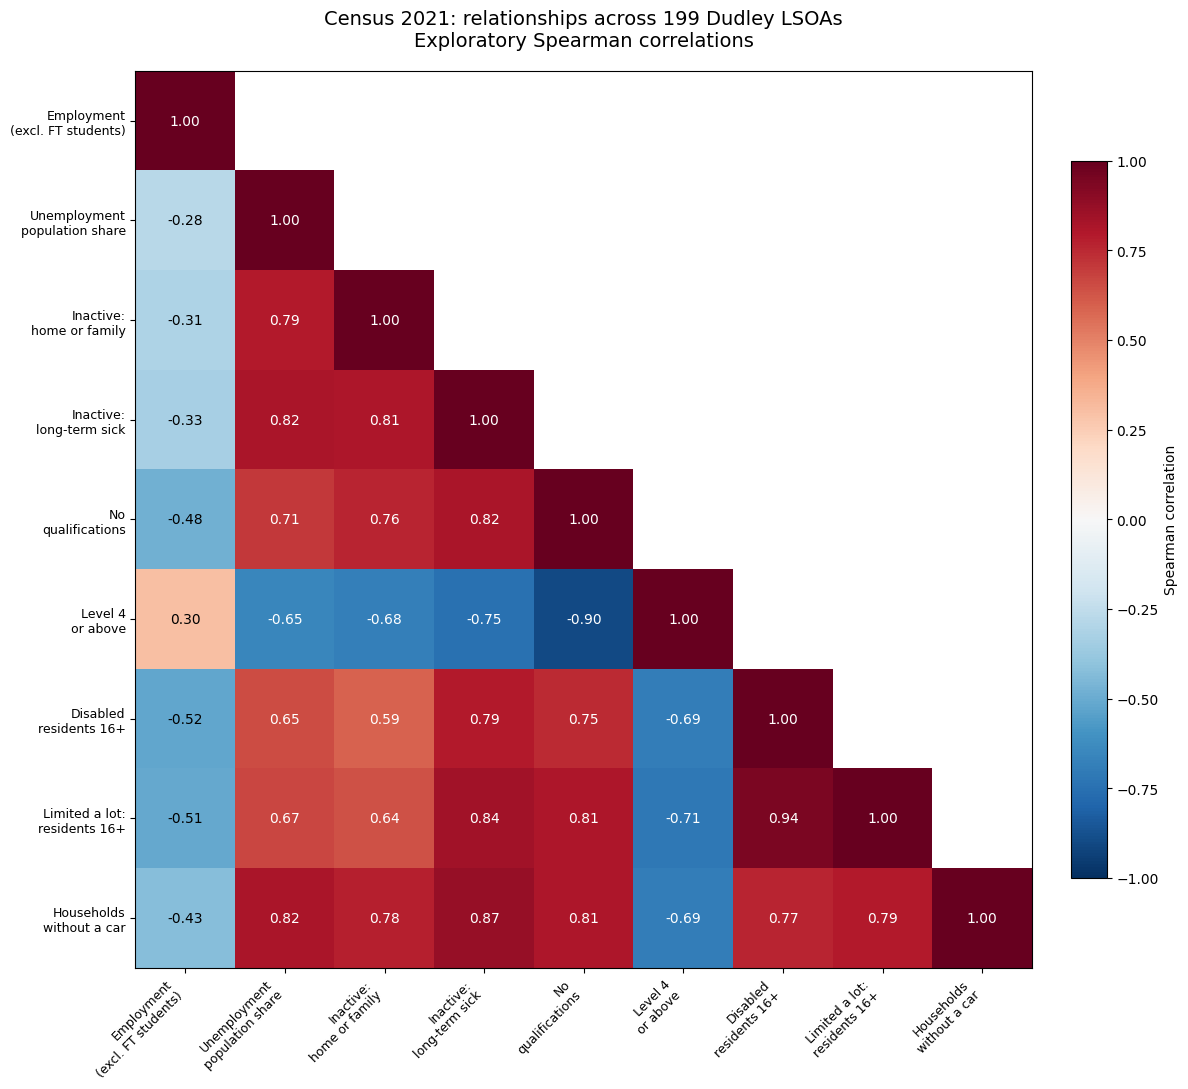

Saved: visualisations/census_spearman_correlations.png


In [12]:
%matplotlib inline

# Developed with ChatGPT assistance to explore Census correlations.

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Calculate rank-based correlations across all included LSOAs.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html
spearman_corr = df[census_measures].corr(
    method="spearman"
)

correlation_labels = [
    "Employment\n(excl. FT students)",
    "Unemployment\npopulation share",
    "Inactive:\nhome or family",
    "Inactive:\nlong-term sick",
    "No\nqualifications",
    "Level 4\nor above",
    "Disabled\nresidents 16+",
    "Limited a lot:\nresidents 16+",
    "Households\nwithout a car"
]

# Hide the repeated upper triangle while retaining the diagonal.
# Reference:
# https://numpy.org/doc/stable/reference/generated/numpy.triu.html
upper_triangle = np.triu(
    np.ones(spearman_corr.shape, dtype=bool),
    k=1
)
masked_corr = np.ma.masked_where(
    upper_triangle,
    spearman_corr.to_numpy()
)

fig, ax = plt.subplots(figsize=(14, 11))

heatmap = ax.imshow(
    masked_corr,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    aspect="equal"
)

ax.set_xticks(range(len(correlation_labels)))
ax.set_xticklabels(
    correlation_labels,
    rotation=45,
    ha="right",
    fontsize=9
)
ax.set_yticks(range(len(correlation_labels)))
ax.set_yticklabels(
    correlation_labels,
    fontsize=9
)

# Label each visible correlation.
for row in range(len(correlation_labels)):
    for column in range(row + 1):
        value = spearman_corr.iloc[row, column]
        ax.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=(
                "white"
                if abs(value) > 0.55
                else "black"
            ),
            fontsize=10
        )

ax.set_title(
    "Census 2021: relationships "
    "across 199 Dudley LSOAs\n"
    "Exploratory Spearman correlations",
    fontsize=14,
    pad=18
)

colour_bar = fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.8,
    pad=0.03
)
colour_bar.set_label("Spearman correlation")

fig.tight_layout()

Path("visualisations").mkdir(exist_ok=True)
figure_path = (
    "visualisations/"
    "census_spearman_correlations.png"
)
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print(f"Saved: {figure_path}")

### Findings

The Spearman correlations show several strong area-level associations
across the 199 included LSOAs. Values below are rounded to two decimals.

- Households without a car are positively associated with inactivity
  due to long-term sickness or disability (0.87), unemployment
  population share (0.82), and no qualifications (0.81).
- Unemployment population share is positively associated with
  long-term sickness or disability inactivity (0.82) and home or
  family inactivity (0.79).
- No qualifications and Level 4 or above qualifications have a strong
  negative association (-0.90). These are separate categories within
  the same qualifications total, which constrains their relationship.
- Disability and activities limited a lot have a correlation of 0.94.
  The latter is a subgroup of the former, so this is not independent
  evidence of two separate barriers.
- Employment share has weaker associations with these measures,
  including disability (-0.52), no qualifications (-0.48), households
  without a car (-0.43), and Level 4 or above qualifications (0.30).

Employment and unemployment population shares are not complements:
residents aged 16 and over also include economically inactive people
and full-time students. Their correlation of -0.28 should be
interpreted in that context.

The results suggest that several characteristics cluster geographically.
They do not establish that the same people experience each circumstance
or that one characteristic causes another.

Shared denominators, overlapping definitions, age composition and
other unmeasured factors may contribute to these relationships.
Strong correlations between potential predictors also warrant attention
if several are used together in a later model.

These are exploratory associations, not formal hypothesis-test results.
Relationships selected after viewing this chart should be identified
as informed by the EDA rather than independently confirmed.

---

## 10. Compare Census measures across historical IMD deciles

Group the 199 included LSOAs by their national IoD2019 IMD decile
and calculate median Census percentages within each group.

Compare unemployment population share, no qualifications, disability
and households without a car or van. Use separate panels because
the measures have different meanings and denominators.

Decile 1 represents the most deprived tenth of English LSOAs;
decile 10 represents the least deprived tenth. Display the number
of included areas in each group because group sizes differ.

These are medians of neighbourhood percentages, not pooled percentages
of residents or households. They describe Census 2021 patterns grouped
by historical deprivation and do not measure change over time.

IMD includes employment, education and health domains, so associations
with related Census measures are not independent validation.
This comparison is descriptive and does not establish causation.

Median Census percentages by historical IMD decile:
                    Number_of_LSOAs  Unemployed_Excl_FT_Students_Pct  No_Qualifications_Pct  Disabled_16_Plus_Pct  No_Car_Van_Households_Pct
IoD2019_IMD_Decile                                                                                                                          
1                                20                             5.49                  30.94                 26.62                      34.28
2                                30                             3.96                  27.78                 25.23                      26.84
3                                26                             3.66                  26.45                 24.06                      23.07
4                                21                             2.94                  23.74                 23.53                      20.65
5                                21                             2.66                  22.13           

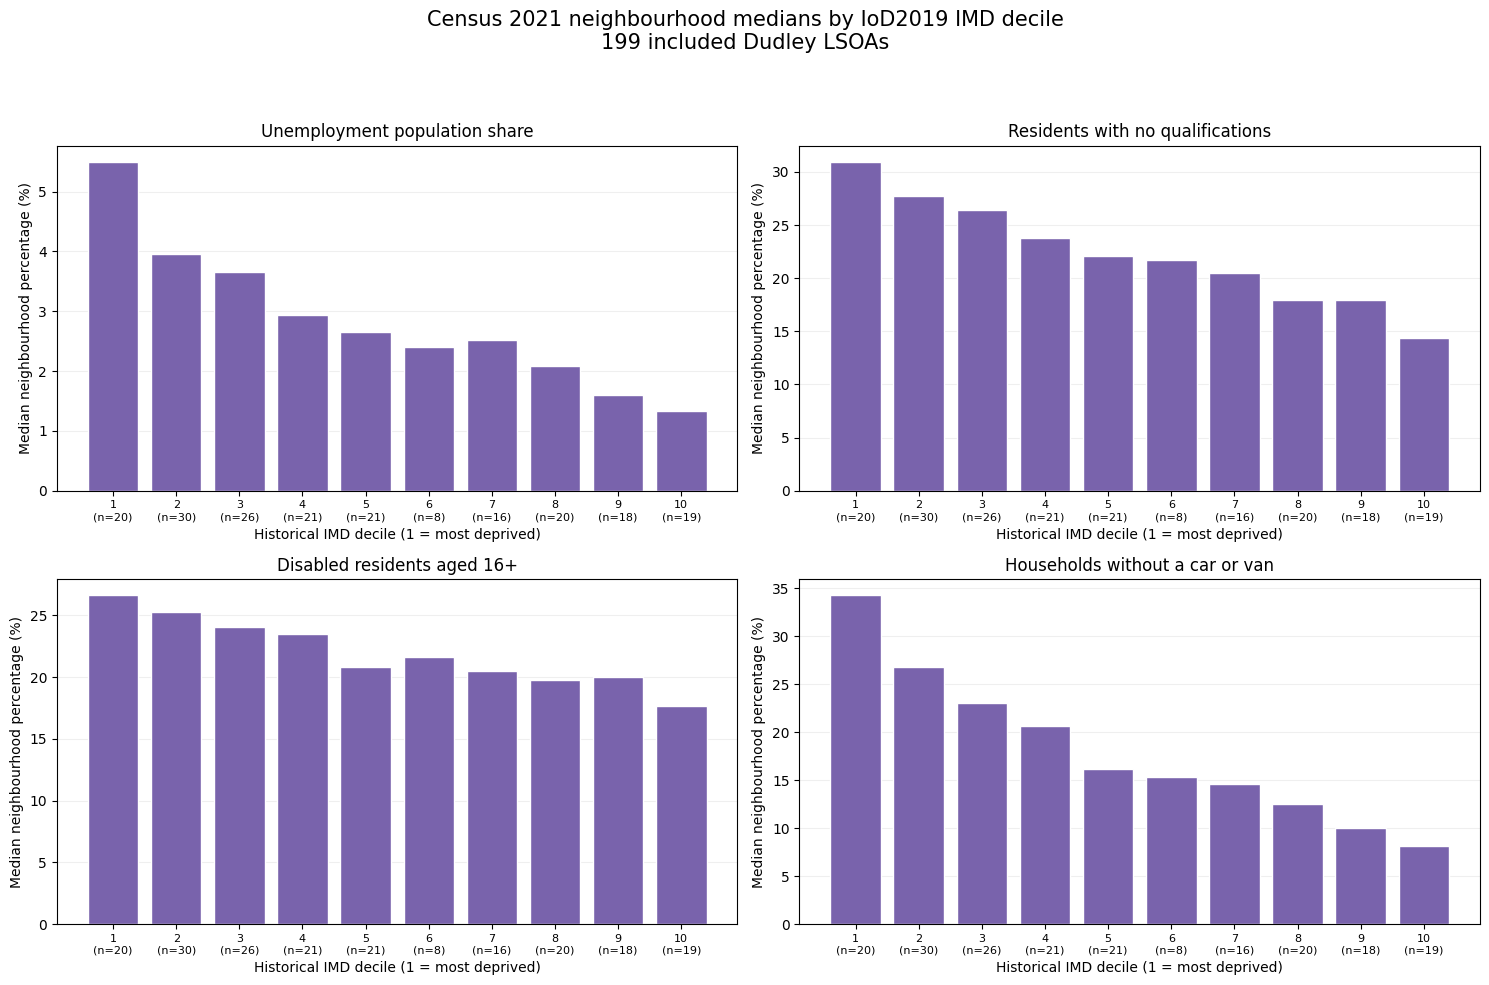

Saved: visualisations/census_by_imd_decile.png


In [13]:
%matplotlib inline

# Developed with ChatGPT assistance to compare historical IMD groups.

import matplotlib.pyplot as plt
from pathlib import Path

decile_measures = [
    "Unemployed_Excl_FT_Students_Pct",
    "No_Qualifications_Pct",
    "Disabled_16_Plus_Pct",
    "No_Car_Van_Households_Pct"
]

decile_labels = [
    "Unemployment population share",
    "Residents with no qualifications",
    "Disabled residents aged 16+",
    "Households without a car or van"
]

# Group areas by IMD decile and calculate each group's medians.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.median.html
decile_medians = (
    df.groupby("IoD2019_IMD_Decile")[decile_measures]
    .median()
    .reindex(range(1, 11))
)

decile_area_counts = (
    df.groupby("IoD2019_IMD_Decile")
    .size()
    .reindex(range(1, 11), fill_value=0)
)

decile_summary = decile_medians.copy()
decile_summary.insert(
    0,
    "Number_of_LSOAs",
    decile_area_counts
)

print(
    "Median Census percentages "
    "by historical IMD decile:"
)
print(decile_summary.round(2).to_string())

fig, axes = plt.subplots(
    2, 2, figsize=(15, 10)
)

tick_labels = [
    f"{decile}\n"
    f"(n={decile_area_counts.loc[decile]})"
    for decile in decile_medians.index
]

for ax, column, label in zip(
    axes.flat,
    decile_measures,
    decile_labels
):
    ax.bar(
        decile_medians.index,
        decile_medians[column],
        color="#7963AC",
        edgecolor="white"
    )

    ax.set_title(label, fontsize=12)
    ax.set_xticks(range(1, 11))
    ax.set_xticklabels(tick_labels, fontsize=8)
    ax.set_xlabel(
        "Historical IMD decile (1 = most deprived)"
    )
    ax.set_ylabel(
        "Median neighbourhood percentage (%)"
    )
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Census 2021 neighbourhood medians "
    "by IoD2019 IMD decile\n"
    "199 included Dudley LSOAs",
    fontsize=15
)
fig.tight_layout(rect=[0, 0, 1, 0.94])

Path("visualisations").mkdir(exist_ok=True)
figure_path = (
    "visualisations/census_by_imd_decile.png"
)
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print(f"Saved: {figure_path}")

### Findings

All four selected Census measures have higher neighbourhood medians
in the most deprived historical IMD decile than in the least deprived.

Comparing decile 1 with decile 10:
- Unemployment population share: 5.49% versus 1.33%.
- No qualifications: 30.94% versus 14.40%.
- Disabled residents aged 16 and over: 26.62% versus 17.67%.
- Households without a car or van: 34.28% versus 8.19%.

The median share of households without a car decreases at every
successive decile. The other measures show an overall downward
pattern with small reversals between some neighbouring deciles.

Group sizes range from 8 LSOAs in decile 6 to 30 in decile 2.
The charts show group medians and do not display the variation
between neighbourhoods within each decile.

These findings connect historical deprivation with Census 2021
area characteristics. They do not demonstrate changes over time
or establish that deprivation causes the observed differences.

IMD includes employment, education and health domains, so associations
with related Census measures partly reflect overlapping concepts.
These comparisons should not be treated as independent validation.

The results describe neighbourhood medians, not pooled resident or
household percentages, and do not determine individual support needs.

---

## 11. Inspect selected relationships with scatter plots

Plot three relationships across all 199 included LSOAs:

- Households without a car versus unemployment population share.
- No qualifications versus unemployment population share.
- Disability versus employment population share.

These pairs explore transport-related circumstances, qualifications
and disability alongside economic activity. They were selected after
reviewing the exploratory correlations.

Each point represents one neighbourhood. Inspect the direction,
shape, spread and any isolated observations. Correlation coefficients
alone cannot show these features.

No regression line or significance test is added at this stage.
The plots do not establish causation or individual support needs.
All observations remain included.

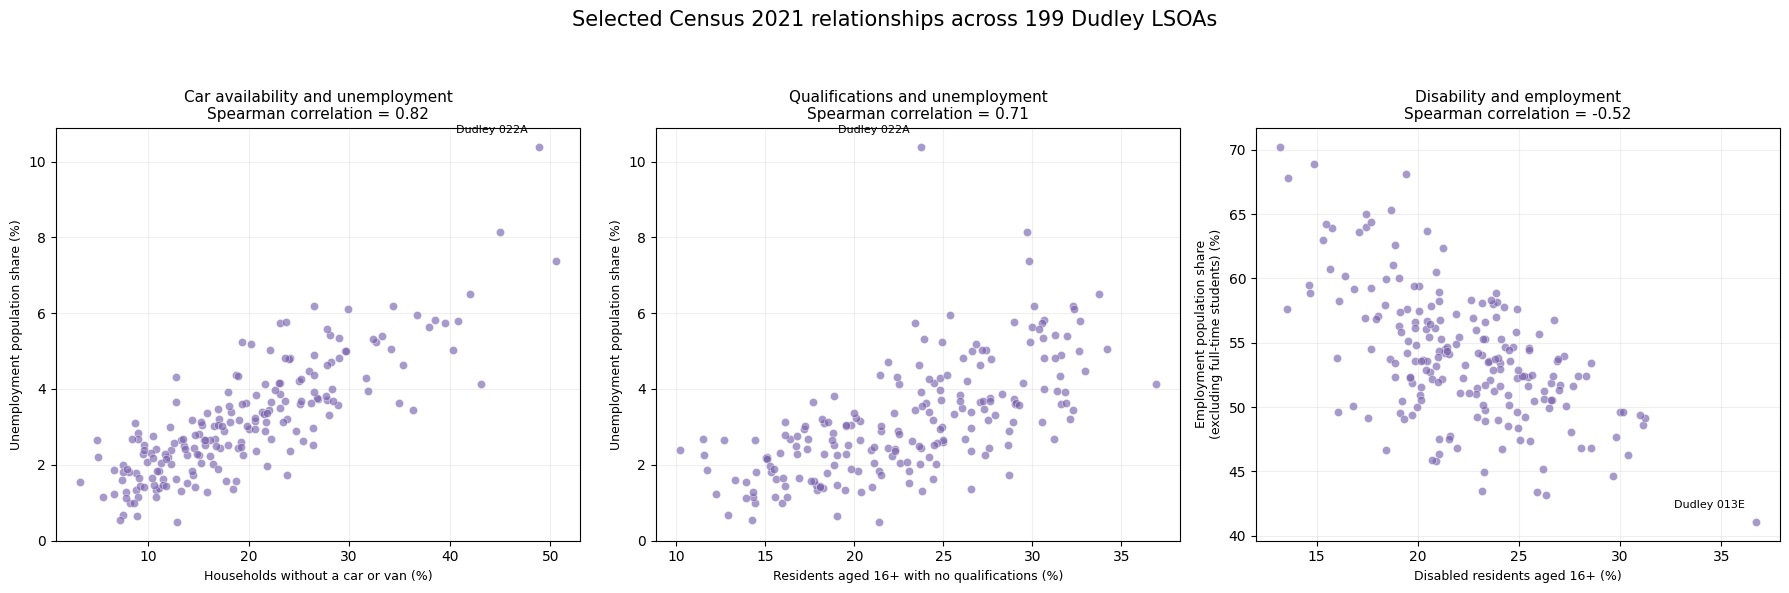

Saved: visualisations/selected_census_relationships.png


In [14]:
%matplotlib inline

# Developed with ChatGPT assistance to inspect selected relationships.

import matplotlib.pyplot as plt
from pathlib import Path

scatter_pairs = [
    (
        "No_Car_Van_Households_Pct",
        "Unemployed_Excl_FT_Students_Pct",
        "Households without a car or van (%)",
        "Unemployment population share (%)",
        "Car availability and unemployment"
    ),
    (
        "No_Qualifications_Pct",
        "Unemployed_Excl_FT_Students_Pct",
        (
            "Residents aged 16+ "
            "with no qualifications (%)"
        ),
        "Unemployment population share (%)",
        "Qualifications and unemployment"
    ),
    (
        "Disabled_16_Plus_Pct",
        "Employed_Excl_FT_Students_Pct",
        "Disabled residents aged 16+ (%)",
        (
            "Employment population share\n"
            "(excluding full-time students) (%)"
        ),
        "Disability and employment"
    )
]

fig, axes = plt.subplots(
    1, 3, figsize=(18, 6)
)

for ax, (
    x_col,
    y_col,
    x_label,
    y_label,
    title
) in zip(axes, scatter_pairs):
    ax.scatter(
        df[x_col],
        df[y_col],
        color="#7963AC",
        alpha=0.65,
        s=35,
        edgecolors="white",
        linewidths=0.4
    )

    # Reuse the Spearman coefficient calculated across all 199 areas.
    correlation = spearman_corr.loc[x_col, y_col]

    ax.set_title(
        f"{title}\n"
        f"Spearman correlation = {correlation:.2f}",
        fontsize=11
    )
    ax.set_xlabel(x_label, fontsize=9)
    ax.set_ylabel(y_label, fontsize=9)
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

    # Label the area with the highest unemployment share in the
    # first two panels, and the highest disability share in the third.
    label_column = (
        y_col
        if y_col.startswith("Unemployed")
        else x_col
    )
    label_index = df[label_column].idxmax()

    # Offset the label from its point to keep the marker visible.
    # Reference:
    # https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.annotate.html
    ax.annotate(
        df.loc[label_index, "LSOA_Name"],
        xy=(
            df.loc[label_index, x_col],
            df.loc[label_index, y_col]
        ),
        xytext=(-8, 10),
        textcoords="offset points",
        ha="right",
        fontsize=8
    )

fig.suptitle(
    "Selected Census 2021 relationships "
    "across 199 Dudley LSOAs",
    fontsize=15
)
fig.tight_layout(rect=[0, 0, 1, 0.93])

Path("visualisations").mkdir(exist_ok=True)
figure_path = (
    "visualisations/"
    "selected_census_relationships.png"
)
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print(f"Saved: {figure_path}")

### Findings

The scatter plots show the direction and spread of the relationships
summarised by the Spearman correlations.

- Households without a car and unemployment population share show
  a clear upward pattern (0.82). Neighbourhoods with similar no-car
  shares still have different unemployment shares.
- No qualifications and unemployment population share also show
  an upward pattern (0.71), with considerable variation around it.
- Disability and employment population share show a downward pattern
  (-0.52), but employment varies substantially between areas with
  similar disability shares.

Dudley 022A stands apart with an unemployment population share of
10.40%. Its no-qualifications share is near the overall area median,
showing that this single measure does not explain its unusual
unemployment share.

Dudley 013E has the highest disability share (36.73%) and the lowest
employment share (41.07%) among the included areas. Its percentages
passed the earlier internal arithmetic checks.

These observations remain in the analysis. Their influence on any
later fitted model should be assessed rather than assumed from their
position on a plot.

The plots do not establish individual relationships or causation.
They also do not, by themselves, demonstrate that a linear model
would meet its assumptions.

---

## 12. Save the EDA summary tables

Export the descriptive statistics, deprivation decile counts,
unusual-value checks, neighbourhood comparisons and correlations
to `outputs/eda`.

Keep meaningful row labels, such as measure names and IMD deciles,
as named columns in the exported files.

Preserve numerical precision in the CSV files. Rounding used in
displayed tables does not change the underlying results.

These exports document the exploratory analysis. The prepared
dataset remains unchanged, with all 199 LSOAs retained.

In [15]:
# Developed with ChatGPT assistance to export EDA summary tables.

from pathlib import Path

output_folder = Path("outputs/eda")
output_folder.mkdir(parents=True, exist_ok=True)

# Convert meaningful index labels into explicit columns for export.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html
eda_tables = {
    "census_descriptive_statistics.csv": (
        census_summary.rename_axis("Measure").reset_index()
    ),
    "deprivation_descriptive_statistics.csv": (
        deprivation_summary.rename_axis("Measure").reset_index()
    ),
    "imd_decile_counts.csv": decile_counts.reset_index(),
    "iqr_screening_summary.csv": iqr_summary,
    "flagged_area_values.csv": flagged_values,
    "flagged_value_checks.csv": flagged_inspection,
    "flagged_area_median_differences.csv": (
        median_differences.rename_axis("LSOA_Name").reset_index()
    ),
    "census_spearman_correlations.csv": (
        spearman_corr.rename_axis("Measure").reset_index()
    ),
    "census_medians_by_imd_decile.csv": (
        decile_summary.reset_index()
    )
}

# Save without an extra index or additional rounding.
for filename, table in eda_tables.items():
    output_path = output_folder / filename
    table.to_csv(output_path, index=False)

    print(
        f"Saved: {output_path.as_posix()} "
        f"({table.shape[0]} rows, {table.shape[1]} columns)"
    )

print(f"\nTables exported: {len(eda_tables)}")
print(f"LSOAs retained in the analysis: {len(df)}")

Saved: outputs/eda/census_descriptive_statistics.csv (9 rows, 10 columns)
Saved: outputs/eda/deprivation_descriptive_statistics.csv (5 rows, 9 columns)
Saved: outputs/eda/imd_decile_counts.csv (10 rows, 2 columns)
Saved: outputs/eda/iqr_screening_summary.csv (9 rows, 6 columns)
Saved: outputs/eda/flagged_area_values.csv (18 rows, 5 columns)
Saved: outputs/eda/flagged_value_checks.csv (18 rows, 10 columns)
Saved: outputs/eda/flagged_area_median_differences.csv (13 rows, 10 columns)
Saved: outputs/eda/census_spearman_correlations.csv (9 rows, 10 columns)
Saved: outputs/eda/census_medians_by_imd_decile.csv (10 rows, 6 columns)

Tables exported: 9
LSOAs retained in the analysis: 199


### Findings

Nine EDA tables were exported successfully to `outputs/eda`.

The exports include descriptive statistics, IMD decile counts,
IQR screening, flagged-value checks, neighbourhood comparisons
and Spearman correlations.

Meaningful row labels were preserved as columns, and no additional
rounding was applied during export. All 199 LSOAs remain in the
analysis, and the prepared dataset was not modified.

---

## 13. EDA conclusion and limitations

### Conclusion

The analysis shows that employment-related circumstances vary across
the 199 included Dudley neighbourhoods. Several characteristics occur
together, but neighbourhoods do not all share the same profile.

Unemployment population share is positively associated with households
without a car or van (Spearman correlation 0.82) and residents with
no qualifications (0.71). Disability share is negatively associated
with employment share (-0.52), although employment varies considerably
between areas with similar disability shares.

Neighbourhoods in the most deprived historical IMD deciles generally
have higher median unemployment population shares, no qualifications,
disability and households without a car.

These patterns suggest that further investigation should consider
training opportunities, accessible employment, caring responsibilities
and travel to work together. The data do not establish individual
support needs or demonstrate which interventions would be effective.

### Data quality and unusual values

The dataset contains 199 unique LSOAs, with no missing values or
duplicate rows. All nine selected Census percentages fall between
0 and 100.

IQR screening flagged 18 observations across 13 neighbourhoods.
Their percentages matched the underlying counts and source-specific
denominators. No observations were removed.

### Limitations

- Four unmatched Census areas were excluded, so the analysis does
  not cover all 203 Dudley Census LSOAs.
- Census 2021 and historical IoD2019 describe different periods
  and should not be presented as current conditions.
- Area-level associations do not establish individual relationships
  or causation.
- Age composition, other unmeasured factors and similarities between
  neighbouring areas may influence the patterns.
- Measures use different denominators. Household percentages cannot
  be interpreted as percentages of residents.
- Unemployment population share is not an unemployment rate.
  Selected inactivity categories do not represent total inactivity.
- Some measures overlap or share denominators. IMD includes domains
  related to employment, education and health.
- Neighbourhood averages and medians are not pooled Dudley percentages.
- Disability does not imply inability to work, no qualifications
  does not mean no skills, and no car does not necessarily mean
  poor transport access.


---

## Ethical Considerations — Exploratory Data Analysis

### Purpose and Responsible Use

This notebook explores the distributions, variation and relationships within the prepared Dudley dataset. Its purpose is to understand the available evidence and inform later hypothesis testing, rather than establish that particular structural barriers cause economic inactivity.

Exploration should remain open to findings that challenge the initial expectations. Measures, charts and observations should not be selected solely because they support the project’s proposed explanation.

### Loading the Prepared Dataset

Using the saved prepared dataset provides a consistent starting point for analysis. Its documented source definitions, geographic exclusions and validation results should remain connected to the exploratory findings.

A successfully loaded file is not sufficient evidence that every variable is suitable for a proposed comparison. The analyst should still consider its meaning, units, denominator and reference period before using it.

Exploratory work should preserve the prepared input file. Any additional variables or transformations should be explained and distinguishable from the original columns.

### Understanding Geographic Coverage

The prepared dataset contains 199 Dudley LSOAs confirmed as having unchanged boundaries between 2011 and 2021. These areas do not provide complete coverage of all 203 Dudley Census 2021 neighbourhoods.

The four excluded Census areas and two deprivation-only areas should remain documented. Their absence should not be interpreted as evidence that they have fewer barriers or less need for support.

Patterns should be described as applying to the included areas. The findings should not silently be generalised to excluded neighbourhoods.

### Selecting Variables for Exploration

Variable selection should follow the research question and documented definitions. Health limitations, formal qualifications, household car availability and economic activity categories describe different dimensions of neighbourhood circumstances.

Choosing a convenient numeric column does not establish that it measures the intended concept. In particular, no car availability is a limited indicator relevant to transport barriers, while no qualifications measures formal attainment rather than all skills.

Identifiers, counts, percentages, composite scores, rates, ranks and deciles should be distinguished before analysis. Numeric storage does not make these fields directly comparable.

### Descriptive Statistics

Summary statistics help describe the range and typical values across neighbourhoods, but they can conceal differences between areas. Means, medians, quartiles and extremes should be interpreted together where relevant.

An unweighted average of neighbourhood percentages gives each included LSOA equal weight. It should not be labelled as the percentage of Dudley residents or households experiencing a condition.

A pooled percentage requires the appropriate summed numerator and denominator for the included areas. It would still describe the included coverage rather than automatically represent the whole borough.

### Population Counts and Percentages

Counts and percentages answer different questions. Counts describe the number of people or households recorded in a category, while percentages describe that category relative to its source population.

Larger neighbourhoods may have higher counts without having higher proportions. Comparisons should explain which measure is being used rather than switching between counts and percentages to produce a stronger-looking pattern.

Each percentage should retain its source-specific denominator. Economic activity, qualification and disability measures refer to residents aged 16 and over, while car availability measures refer to households.

### Exploring Distributions

Distribution charts help reveal concentration, spread, asymmetry and unusual values. Their presentation should show the observed variation without suggesting that one distribution shape is inherently desirable.

Histogram intervals and axis limits can change how patterns appear. These choices should support a clear view of the data rather than exaggerate clustering or conceal differences.

A skewed distribution does not establish that the data is wrong. It may reflect genuine variation between neighbourhoods and should inform the interpretation and choice of later methods.

### Investigating Unusual Values

High or low observations should be investigated rather than removed automatically. An unusual value may identify a genuine neighbourhood circumstance that is important to the research question.

Excluding valid extremes could understate inequality or hide areas experiencing substantial barriers. Any removal should have a documented reason based on a source or processing issue.

If a value is retained after investigation, its interpretation should remain respectful. An extreme percentage should not be used to characterise every resident in that neighbourhood.

### Comparing Neighbourhoods

Neighbourhood comparisons should recognise differences in population composition, household structure and local circumstances. Similar percentages do not necessarily arise from the same underlying processes.

Ranking areas can make differences easy to see, but it can also encourage simplistic labels. A higher value should not automatically be interpreted as evidence of failure, unwillingness to work or a single identifiable cause.

Descriptions should focus on the measured characteristic and reference period rather than assigning a fixed identity to a neighbourhood.

### Exploring Relationships Between Variables

Scatter plots and other relationship charts can reveal patterns worth investigating. They cannot establish whether one variable causes another, whether the direction runs the other way, or whether additional factors influence both.

Observed relationships may reflect age structure, caring responsibilities, income, housing, employment opportunities or other circumstances not fully represented in the dataset.

A visible trend should be described as an area-level association. It should not be presented as proof that changing one measure would produce a particular change in economic inactivity.

### Interpreting Correlations

Correlation summaries describe relationships within the included data and depend on the variables and method selected. They do not establish causation or estimate the independent contribution of each barrier.

A strong correlation does not show that a measure is the most important cause. A weak correlation does not establish that a barrier is unimportant to individual residents or particular groups.

Exploring many relationships increases the opportunity to notice striking patterns by chance. Relationships selected after inspecting the data should be acknowledged as exploratory rather than presented as predictions specified independently in advance.

### Avoiding Conceptual Overlap

Some measures contain related concepts. Health limitations overlap conceptually with economic inactivity attributed to long-term sickness or disability.

Historical deprivation measures may also contain health, employment or education information. Associations with related Census variables may therefore partly reflect overlapping definitions.

These relationships can still be informative, but they should not be presented as entirely independent confirmation of the project’s assumptions.

### Interpreting Economic Activity Categories

The available economic activity extract contains selected categories rather than a complete measure of economic inactivity. Employment and unemployment categories also retain their stated exclusion of full-time students.

Charts and descriptions should preserve these qualifications. An unemployed count divided by all residents aged 16 and over should not be labelled as an unemployment rate based on the economically active population.

Where the selected-inactivity outcome is discussed, it should be clearly defined as home or family responsibilities, long-term sickness or disability, and other inactivity reasons. It excludes retirement and inactive students from its numerator while retaining all residents aged 16 and over in its denominator.

### Respectful Interpretation of Health and Qualifications

Disability should not be interpreted as evidence of inability or unwillingness to work. Its relationship with economic activity may involve accessibility, available support, job requirements and other circumstances that the data does not measure directly.

Having no formal qualifications does not mean having no skills, experience or capacity to learn. Qualification patterns should not be used to judge individual residents or imply that educational attainment alone explains inactivity.

Both measures should be discussed as part of the wider context rather than as personal deficiencies.

### Interpreting Car Availability

The percentage of households without a car or van should not be presented as a direct measurement of transport poverty. Public transport, walking routes, travel costs, service frequency and access to employment are not fully captured by vehicle availability.

A household with a vehicle may still experience transport barriers, and a household without one may have suitable alternatives.

Household vehicle availability also does not establish whether each resident can use a vehicle. Comparisons with person-based economic activity measures must acknowledge this difference.

### Historical Deprivation Context

IoD2019 and Census 2021 measures refer to different periods, and the underlying dates within the deprivation release vary. Their combination provides historical context rather than a simultaneous measurement of neighbourhood conditions.

National ranks and deciles should retain their national meaning after the dataset is restricted to Dudley. They should not be interpreted as locally calculated rankings or percentages of residents experiencing deprivation.

Composite deprivation scores should not be compared as though every domain shares the same numerical scale.

### Spatial Dependence

Neighbouring areas may share transport services, employment opportunities, housing conditions and other influences. The 199 observations should not automatically be regarded as independent examples of unrelated circumstances.

Clusters of similar values may reflect shared local conditions. Ordinary exploratory correlations do not account for these spatial relationships by themselves.

This limitation should remain visible when exploratory findings are used to motivate later statistical testing.

### Honest and Accessible Visualisation

Chart titles, axis labels and legends should identify the measure, units and relevant population clearly. Labels should distinguish households from people and historical figures from current conditions.

Axis limits, colour scales and category ordering should help readers understand the evidence without overstating small differences. Where a scale is restricted, its limits should remain clear.

Colour should not be the only way to communicate meaning. Readable text, sufficient contrast and accompanying written findings help make the analysis accessible to a wider audience.

Colours and labels should also avoid implying that residents or neighbourhoods are inherently good or bad.

### Area-Level Interpretation and Privacy

The analysis concerns aggregated neighbourhood statistics. It should not attempt to identify individuals or infer a particular resident’s health, qualifications, vehicle access or employment status.

An association between two area percentages does not establish that the same people belong to both categories. Drawing that conclusion would exceed what the data can show.

Maps, tables and charts should communicate patterns without stigmatising communities or encouraging individual profiling.

### Recording Findings Without Overclaiming

Written findings should distinguish direct observations from possible explanations. A description of what a chart shows can be supported by the data, while an explanation of why the pattern occurs may require additional evidence.

Unexpected or weak relationships should be reported alongside stronger ones where they are relevant. Conclusions should not omit contradictory evidence simply to make the project narrative more convincing.

Numerical precision should be appropriate to the data. Additional decimal places should not imply greater certainty than the measures support.

### Exporting Charts and Summary Tables

Exported figures and tables should remain traceable to the notebook and prepared data. File names, labels and accompanying explanations should make their content understandable when viewed outside the notebook.

Exports should retain enough context to prevent selected categories, denominators or reference years from being misunderstood. A chart separated from its explanatory text should not suggest a stronger conclusion than the full analysis supports.

Saving outputs successfully does not replace checking that labels, values and formatting accurately represent the intended results.

### Relationship to Hypothesis Testing

Exploratory analysis helps identify patterns and choose questions for further investigation. Hypothesis tests developed after viewing the same dataset should be described as informed by that exploration.

Testing those relationships on the same observations does not provide independent confirmation. Later results should acknowledge the exploratory process and the assumptions of the statistical methods used.

Neither exploratory charts nor subsequent significance tests establish causal effects or remove the limitations of area-level data.

### Transparency and Accountability

Code comments, references and findings should explain the choices made during exploration, including variable selection, transformations, chart design and interpretation. ChatGPT assistance should remain acknowledged.

The analyst remains responsible for checking outputs and ensuring that conclusions reflect the evidence. Findings may inform discussion of local barriers, but they should not be used alone to make decisions about individual residents or prescribe interventions without further context.

---